# Estado del arte: estimadores de duración y EM, matrices condicionadas a la macro y una biblioteca de referencia

**Pregunta:** ¿Qué estimador debe usar un banco para leer la PD a un año y a cinco años de un grado de calificación a partir de datos de migración, cuando los mejores grados casi no registran incumplimientos: el estimador de cohortes de la industria, el estimador de duración, EM o una de las reparaciones de la matriz agrupada; y siguen discrepando en la matriz real de S&P?

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los notebooks 02 y 03 de este tema (los estimadores y los generadores)
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este notebook puedes:

- enunciar las prácticas que encontró la investigación para estimar una matriz de transición de calificaciones: los estimadores de cohortes y de duración, las reparaciones de la matriz, EM, Aalen-Johansen, las matrices condicionadas a la macro y una biblioteca de referencia;
- comparar seis estimadores de la PD a un año sobre datos cuya verdad se conoce, con el sesgo y el error de cada uno y su error estándar de Monte Carlo, corriendo un estudio pequeño con el generador y el arnés de desempeño del motor;
- leer qué dicen los estimadores sobre la matriz real de S&P, a uno y a cinco años, y qué tan lejos quedan entre sí;
- decir qué hace y qué no hace el producto en cada práctica, y qué comparación con una biblioteca de referencia no se corre.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.engines import vasicek
from riskvalidation.generators.paths import RatingPaths
from riskvalidation.harness.performance import estimator_performance
from riskvalidation.transitions import em, embedding, estimators
from scipy.linalg import expm

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Tres archivos versionados del caso C04, de la publicación CEREP de ESMA (clase de licencia `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/): `data/derived/C04/sp.json` (las cohortes reales de S&P, con sus conteos y retiros, la matriz agrupada y la tasa de incumplimiento del grado especulativo por año), `data/derived/C04/models-transitions.json` (el generador ajustado a S&P, usado aquí como la verdad de una simulación) y `data/derived/C04/markov.json` (el estudio propio del producto: 200 conjuntos de datos con semilla desde ese generador, seis estimadores).

In [2]:
# Load the three committed documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
sp = json.loads((C04 / "sp.json").read_text(encoding="utf-8"))
models = json.loads((C04 / "models-transitions.json").read_text(encoding="utf-8"))
markov = json.loads((C04 / "markov.json").read_text(encoding="utf-8"))
out = sp["outputs"]
grades = out["grades"]

## Método

### Paso 1: juzgar un estimador sobre una verdad conocida

Un estimador se juzga sobre datos cuya verdad se conoce, en muchos conjuntos de datos y nunca en una sola muestra (Morris, White y Crowther, 2019). Para cada estimador $\hat\theta$ de una PD $\theta$ en $n$ conjuntos, el arnés del motor informa el sesgo $\bar{\hat\theta} - \theta$, el error estándar empírico, la raíz del error cuadrático medio (RMSE) y, de cada uno, su error estándar de Monte Carlo: cuánto se movería el número con otros conjuntos de datos. El RMSE relativo (RMSE sobre $\theta$) se lee como "el error típico es esta fracción de la PD". Compiten seis estimadores: la matriz de **cohortes** agrupada de fotos anuales, el generador de **duración** (Lando y Skodeberg, 2002), el generador **EM** de las fotos (Bladt y Sørensen, 2005; Smith y dos Reis, 2018) y las tres reparaciones de la matriz agrupada, **diagonal**, **ponderada** (Israel, Rosenthal y Wei, 2001) y **JLT** (Jarrow, Lando y Turnbull, 1997). La celda siguiente genera 60 conjuntos de datos con semilla de cinco fotos anuales desde el generador ajustado a S&P, con sus deudores por grado, y entrega cada conjunto a los seis estimadores. Toma cerca de un minuto, casi todo en EM.

In [3]:
# Draw 60 seeded datasets and estimate the one-year PD of every grade with six estimators
q_true = np.array(models["fit"]["generator"]["q"], dtype=float)
obligors = tuple(models["fit"]["generator"]["obligors"])
generator = RatingPaths(q_true, obligors, horizon=5.0, snapshots=tuple(float(t) for t in range(6)))
truth = np.array(generator.truth()["one_year_matrix"])[:7, -1]
names = ("cohort", "duration", "em", "diagonal", "weighted", "jlt")
display = {"cohort": "cohortes", "duration": "duración", "em": "EM", "diagonal": "diagonal"}
display |= {"weighted": "ponderada", "jlt": "JLT", "aalen_johansen": "Aalen-Johansen"}
estimates = {name: np.full((60, 7), np.nan) for name in names}
for i, child in enumerate(np.random.SeedSequence(20261021).spawn(60)):
    data = generator.draw(np.random.default_rng(child))
    steps = [{"counts": s["counts"], "dt": 1.0} for s in data["steps"]]
    pooled = estimators.pooled_cohort([s["counts"] for s in data["steps"]])["matrix"]
    estimates["cohort"][i] = pooled[:7, -1]
    estimates["duration"][i] = expm(estimators.duration_generator(data["segments"], 8)["generator"])[:7, -1]
    estimates["em"][i] = expm(em.em_generator(steps)["generator"])[:7, -1]
    for repair in ("diagonal", "weighted", "jlt"):
        estimates[repair][i] = expm(embedding.generator(pooled, method=repair)["generator"])[:7, -1]
print("PD verdadera a un año, puntos base:", np.round(1e4 * truth, 2))
print("conjuntos de datos:", estimates["cohort"].shape[0], "| deudores por grado:", obligors)

PD verdadera a un año, puntos base: [6.6000e-01 4.9000e-01 2.8800e+00 8.1700e+00 3.4620e+01 1.1731e+02
 8.0618e+02]
conjuntos de datos: 60 | deudores por grado: (75, 822, 1814, 1756, 1054, 1391, 201)


La figura muestra lo que cada estimador devolvió para AAA, el grado de menor PD, en cada uno de los 60 conjuntos de datos, en puntos base, con la verdad como línea punteada.

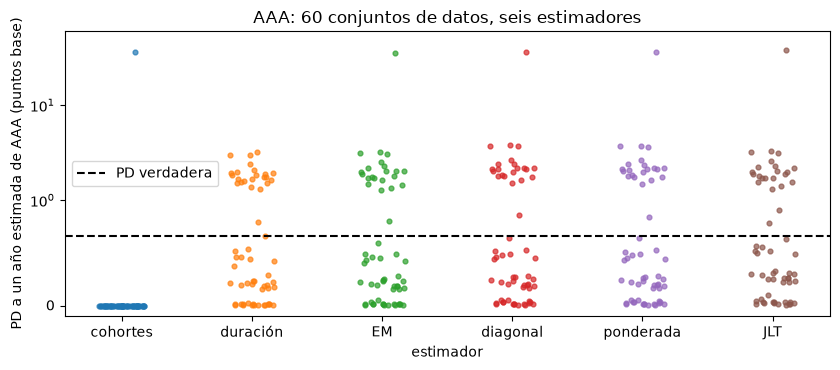

In [4]:
# Draw the 60 AAA estimates of every estimator beside the true PD
fig, ax = plt.subplots(figsize=(8.5, 3.8))
jitter = np.random.default_rng(1).uniform(-0.18, 0.18, size=60)
for k, name in enumerate(names):
    ax.scatter(k + jitter, 1e4 * estimates[name][:, 0], s=12, alpha=0.7)
ax.axhline(1e4 * truth[0], color="black", linestyle="--", label="PD verdadera")
ax.set_yscale("symlog", linthresh=1.0)
ax.set_ylim(-0.1, 60)
ax.set_xticks(range(len(names)))
ax.set_xticklabels([display[name] for name in names])
ax.set_xlabel("estimador")
ax.set_ylabel("PD a un año estimada de AAA (puntos base)")
ax.set_title("AAA: 60 conjuntos de datos, seis estimadores")
ax.legend()
fig.tight_layout()
plt.show()

El estimador de cohortes pone 59 de los 60 conjuntos de datos en exactamente cero y el sexagésimo en 36 puntos base, unas cincuenta y cinco veces la verdad (punteada): todo su error está en el único conjunto en que ocurrió un incumplimiento, pues un grado con una PD de 0,7 puntos base rara vez incumple en unos cientos de años-deudor. EM y las tres reparaciones nunca devuelven exactamente cero, pero comparten ese valor atípico porque parten de las mismas fotos. El estimador de duración no muestra tal valor atípico en estos conjuntos: usa el tiempo pasado en cada grado y da una probabilidad distinta de cero a una transición que no se observó directamente. Un solo conjunto de datos escondería todo esto, por eso el arnés resume muchos.

La celda siguiente entrega las 60 estimaciones de cada grado a `estimator_performance` del motor, que devuelve el sesgo, el RMSE y sus errores estándar de Monte Carlo, e imprime la fila de AAA de cada estimador.

In [5]:
# Bias, RMSE and their Monte Carlo errors by grade, from the engine's performance harness
relative = {}
for name in names:
    rows = [estimator_performance(estimates[name][:, g], truth[g]) for g in range(7)]
    relative[name] = {key: np.array([r[key] for r in rows]) / truth for key in ("bias", "rmse", "rmse_mcse")}

header = ["sesgo rel.", "RMSE rel.", "ee RMSE", "ceros", "mayor (pb)"]
print(f"{'AAA':10s}" + "".join(f"{h:>15s}" for h in header))
for name in names:
    r = relative[name]
    zeros = float(np.mean(estimates[name][:, 0] == 0))
    largest = 1e4 * estimates[name][:, 0].max()
    values = [r["bias"][0], r["rmse"][0], r["rmse_mcse"][0], zeros, largest]
    print(f"{display[name]:10s}" + "".join(f"{v:15.3f}" for v in values))

AAA            sesgo rel.      RMSE rel.        ee RMSE          ceros     mayor (pb)
cohortes           -0.077          7.090          3.475          0.983         36.364
duración            0.266          1.402          0.138          0.000          3.204
EM                  1.115          6.951          3.326          0.000         35.252
diagonal            1.301          7.210          3.409          0.000         36.333
ponderada           1.278          7.156          3.387          0.000         36.082
JLT                 1.269          7.518          3.615          0.000         38.167


La figura dibuja el RMSE relativo de los seis estimadores en los siete grados en un eje logarítmico. Su mensaje es dónde se separan las líneas.

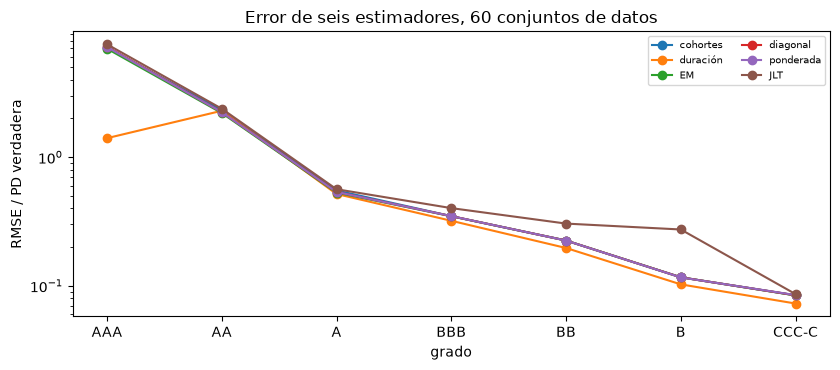

In [6]:
# Draw the relative RMSE of the six estimators by grade from the 60-dataset study
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for name in names:
    ax.plot(range(7), relative[name]["rmse"], marker="o", label=display[name])
ax.set_yscale("log")
ax.set_xticks(range(7))
ax.set_xticklabels(grades)
ax.set_xlabel("grado")
ax.set_ylabel("RMSE / PD verdadera")
ax.set_title("Error de seis estimadores, 60 conjuntos de datos")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

Desde A hacia abajo las seis líneas quedan juntas, con un error típico de cerca de la mitad de la PD en A que baja a una décima en B; la reparación llamada JLT se aleja hacia arriba desde BBB. En AAA y AA el error es un múltiplo de la propia PD: el estimador de duración es cinco veces mejor en AAA, 1,4 frente a cerca de 7, pero el error estándar de Monte Carlo impreso arriba es grande, y lo dice, de modo que el orden de los grados superiores no queda resuelto por este estudio pequeño. El estudio propio del producto, con 200 conjuntos de datos, es el paso siguiente. Se lee, no se vuelve a correr, y dice si el cuadro se sostiene con un error de Monte Carlo menor.

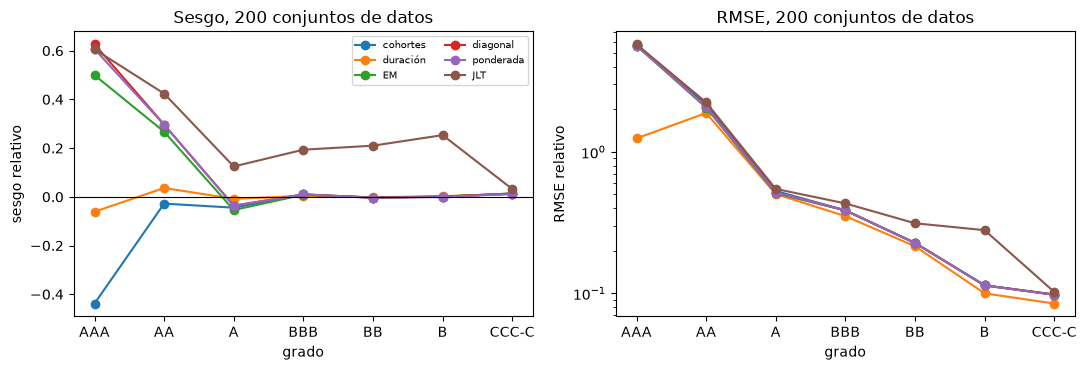

In [7]:
# Draw the relative bias and relative RMSE of the six estimators from the committed 200-dataset study
study = markov["outputs"]["rungs"][0]["estimators"]
truth_200 = np.array(study["cohort"]["truth"])
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
for name in [n for n in names if n in study]:
    left.plot(range(7), np.array(study[name]["bias"]) / truth_200, marker="o", label=display[name])
    right.plot(range(7), np.array(study[name]["rmse"]) / truth_200, marker="o", label=display[name])
left.axhline(0.0, color="black", linewidth=0.8)
right.set_yscale("log")
for panel, label in ((left, "sesgo relativo"), (right, "RMSE relativo")):
    panel.set_xticks(range(7))
    panel.set_xticklabels(grades)
    panel.set_xlabel("grado")
    panel.set_ylabel(label)
left.set_title("Sesgo, 200 conjuntos de datos")
right.set_title("RMSE, 200 conjuntos de datos")
left.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

Con 200 conjuntos de datos el panel izquierdo separa a los estimadores que el estudio pequeño no podía. El estimador de cohortes tiene sesgo hacia abajo en AAA, porque devuelve cero en casi todos los conjuntos, y EM y las reparaciones diagonal y ponderada tienen sesgo hacia arriba ahí, porque nunca devuelven cero. El estimador de duración es el único cercano a sesgo cero en AAA. JLT tiene un sesgo positivo claro de BBB a B. A la derecha, el error de cada estimador es del orden de la PD en AAA y AA y baja de una décima parte de ella hacia CCC-C. Lo que los paneles no muestran es la matriz real: es un generador ajustado a S&P, con su verdad conocida, no S&P mismo.

## Estado del arte

### Lo que encontró la investigación, y lo que hace el producto

- **Cohortes frente a duración.** El estándar de la industria estima la matriz a un año desde fotos anuales, el método de cohortes, quitando los retiros (Anderson y Goodman, 1957; Schuermann y Hanson, 2004). El estimador de duración de Lando y Skodeberg (2002) usa cada salto y el tiempo en cada grado y da probabilidades distintas de cero para transiciones raras. *Producto:* ambos están en el motor; el de cohortes corre sobre las tablas reales de CEREP, el de duración solo donde existen trayectorias, de modo que el producto los compara sobre trayectorias simuladas de verdad conocida (el Paso 1 de arriba y el notebook 02).
- **Reparar la matriz.** La matriz a un año no tiene un generador exacto (Israel, Rosenthal y Wei, 2001); las reparaciones diagonal, ponderada y JLT y EM son la práctica. *Producto:* las cuatro, con la distancia L1 y la PD a cinco años (notebook 03), corridas en vivo abajo sobre la matriz real.
- **Aalen-Johansen** para cadenas no homogéneas en el tiempo. *Producto:* está en el motor y en el notebook 02; se corre abajo sobre los mismos 60 conjuntos de datos.
- **Matrices condicionadas a la macro.** Belkin, Suchower y Forest (1998) condicionan la matriz a un factor $z$ del ciclo de crédito. *Producto:* lee el factor que implica cada año (`vasicek.implied_factor`, notebook 01) y prueba si la matriz es la misma cada año (notebook 04); no ajusta una matriz condicionada a la macro. La celda siguiente lee el factor de cada año desde la tasa de incumplimiento del grado especulativo, que es aquello a lo que se condicionaría tal modelo.
- **Una biblioteca de referencia.** La investigación nombra al paquete `transitionMatrix` como una implementación independiente contra la cual cotejar el estimador de cohortes. *Producto:* las pruebas propias del motor concilian su estimador de cohortes con `transitionMatrix` 0.5.1 (RV-415, anunciado en las notas de la versión 0.8.0 del motor): `pooled_cohort` y `cohort` igualan elemento a elemento al estimador de cohortes del paquete dentro de 1e-12 sobre un panel con semilla y con retiros. Corren donde está instalado el extra opcional `transitions` de la rueda. **Este notebook no las vuelve a correr**: `transitionMatrix` no está entre sus paquetes fijados, así que la igualdad se informa desde el motor y no se cuenta como resultado de aquí. Lo que el notebook muestra es la concordancia de los estimadores propios del producto, que se lee abajo.

In [8]:
# The credit-cycle factor of each year from the speculative-grade default rate
labels = out["mobility"]["labels"]
spec = np.array([np.nan if v is None else v for v in out["mobility"]["spec_default_rate"]])
mean_spec = float(np.nanmean(spec))
rho_spec = 0.12  # the Basel minimum corporate correlation, an assumption of this reading
factor = vasicek.implied_factor(spec, mean_spec, rho_spec)
order = np.argsort(factor)
worst = ", ".join(f"{labels[k]} ({factor[k]:.2f})" for k in order[:4])
best = ", ".join(f"{labels[k]} ({factor[k]:.2f})" for k in order[::-1][:4])
print(f"tasa media de incumplimiento del grado especulativo {mean_spec:.4f}")
print(f"peores años (menor factor): {worst}")
print(f"mejores años (mayor factor): {best}")
print(f"años con factor negativo: {int((factor < 0).sum())} de {len(factor)}")

tasa media de incumplimiento del grado especulativo 0.0375
peores años (menor factor): 2009 (-1.72), 2002 (-1.42), 2001 (-1.35), 2000 (-0.95)
mejores años (mayor factor): 2007 (1.15), 2006 (0.99), 2005 (0.85), 2014 (0.70)
años con factor negativo: 14 de 26


La figura dibuja el factor de cada año; una barra negativa es un año peor que el ciclo promedio.

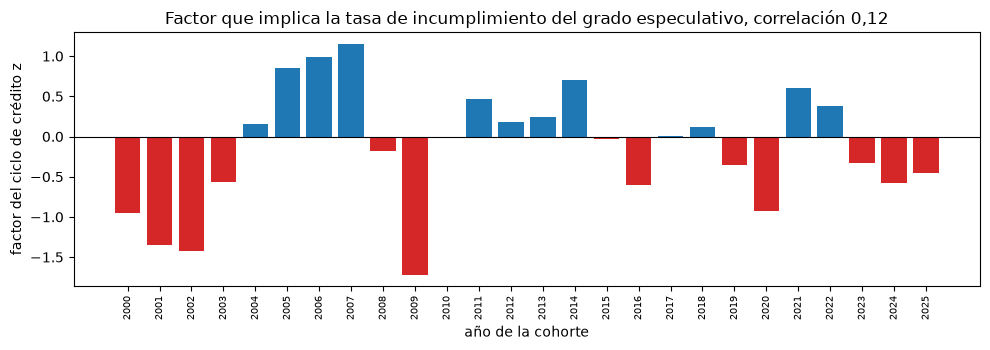

In [9]:
# Draw the credit-cycle factor of each year
fig, ax = plt.subplots(figsize=(10, 3.6))
colours = ["tab:red" if f < 0 else "tab:blue" for f in factor]
ax.bar(range(len(factor)), factor, color=colours)
ax.axhline(0.0, color="black", linewidth=0.8)
ax.set_xticks(range(len(factor)))
ax.set_xticklabels(labels, rotation=90, fontsize=7)
ax.set_xlabel("año de la cohorte")
ax.set_ylabel("factor del ciclo de crédito z")
ax.set_title("Factor que implica la tasa de incumplimiento del grado especulativo, correlación 0,12")
fig.tight_layout()
plt.show()

Los peores años vienen en dos grupos, la burbuja puntocom de 2000 a 2002 y la crisis de 2009, con 2009 el más bajo, y los años entre ellos son positivos. Catorce de los 26 años quedan bajo el ciclo promedio, cerca de la mitad, como debe dar un factor centrado en la media. Una matriz condicionada a la macro usaría este número por año para mover toda la matriz. El producto lee el factor y prueba si la matriz es estable entre años (notebook 04), pero no ajusta la matriz condicionada, y la figura sola no dice cuánto se movería la migración de cada grado con el factor.

In [10]:
# Aalen-Johansen on the same 60 datasets: the non-parametric estimate of the one-year matrix
estimates["aalen_johansen"] = np.full((60, 7), np.nan)
for i, child in enumerate(np.random.SeedSequence(20261021).spawn(60)):
    data = generator.draw(np.random.default_rng(child))
    matrix = estimators.aalen_johansen(data["segments"], 8, 0.0, 1.0)["matrix"]
    estimates["aalen_johansen"][i] = np.array(matrix)[:7, -1]
rows = [estimator_performance(estimates["aalen_johansen"][:, g], truth[g]) for g in range(7)]
keys = ("bias", "rmse", "rmse_mcse")
relative["aalen_johansen"] = {key: np.array([r[key] for r in rows]) / truth for key in keys}
aj = relative["aalen_johansen"]
print("Aalen-Johansen, AAA: sesgo relativo", round(aj["bias"][0], 3), "| RMSE relativo", round(aj["rmse"][0], 3))
print("Aalen-Johansen, CCC-C: sesgo relativo", round(aj["bias"][6], 3), "| RMSE relativo", round(aj["rmse"][6], 3))
others = [round(relative[name]["rmse"][6], 3) for name in ("cohort", "duration")]
print("cohortes y duración, CCC-C, RMSE relativo:", others)

Aalen-Johansen, AAA: sesgo relativo -0.046 | RMSE relativo 2.313
Aalen-Johansen, CCC-C: sesgo relativo 0.0 | RMSE relativo 0.202
cohortes y duración, CCC-C, RMSE relativo: [np.float64(0.084), np.float64(0.073)]


La figura dibuja su RMSE relativo por grado junto a los estimadores de cohortes y de duración de los mismos conjuntos de datos.

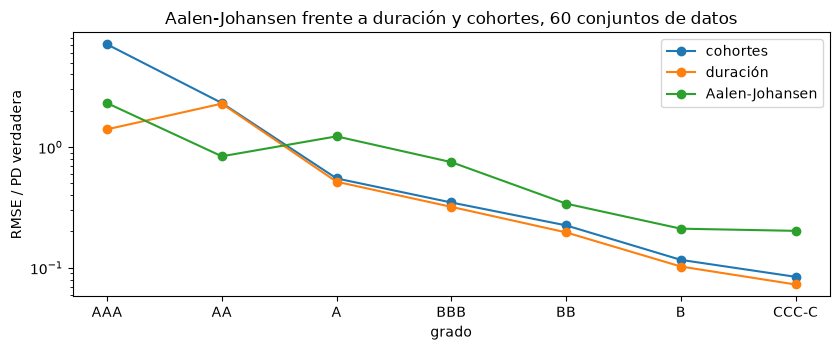

In [11]:
# Draw the relative RMSE of Aalen-Johansen, duration and cohort by grade
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for name in ("cohort", "duration", "aalen_johansen"):
    ax.plot(range(7), relative[name]["rmse"], marker="o", label=display[name])
ax.set_yscale("log")
ax.set_xticks(range(7))
ax.set_xticklabels(grades)
ax.set_xlabel("grado")
ax.set_ylabel("RMSE / PD verdadera")
ax.set_title("Aalen-Johansen frente a duración y cohortes, 60 conjuntos de datos")
ax.legend()
fig.tight_layout()
plt.show()

Aalen-Johansen queda entre los otros dos en AAA y sobre ambos de A hacia abajo, por un factor de dos a tres en BBB y en CCC-C. La razón está en lo que estima. Da la matriz a un año desde los saltos del primer año solamente, una estimación no paramétrica que no supone que la cadena sea la misma cada año, mientras que los estimadores de cohortes y de duración agrupan cinco años porque el generador detrás de los datos es homogéneo en el tiempo. Aquí la verdad es homogénea, de modo que agrupar es lo correcto y Aalen-Johansen paga por no suponerlo; donde la matriz sí cambia de un año a otro, lo que el notebook 04 prueba en S&P, los estimadores agrupados pagarían en sesgo. La baja en AA queda dentro del error de Monte Carlo de 60 conjuntos de datos en un grado delgado y no es un orden.

Ahora los estimadores sobre la matriz real de S&P. La celda siguiente reconstruye la matriz agrupada desde los conteos y retiros de las 26 cohortes, ajusta el generador EM a las 26 tablas anuales, deriva los generadores diagonal, ponderado y JLT desde la matriz agrupada, y toma la PD a un año y a cinco años de cada uno. El estimador de cohortes a cinco años es la matriz agrupada elevada a la quinta, que es lo que da una lectura de Markov sin generador.

In [12]:
# One-year and five-year PD of each estimator on the real S&P matrix
tables = [np.vstack([np.array(c["counts"], dtype=float), np.zeros(8)]) for c in out["cohorts"]]
withdrawn = [np.append(np.array(c["withdrawn"], dtype=float), 0.0) for c in out["cohorts"]]
pooled_real = estimators.pooled_cohort(tables, withdrawn)["matrix"]
generators = {"em": em.em_generator([{"counts": t, "dt": 1.0} for t in tables])["generator"]}
for repair in ("diagonal", "weighted", "jlt"):
    generators[repair] = embedding.generator(pooled_real, method=repair)["generator"]

one_year = {"cohort": pooled_real[:7, 7]}
five_year = {"cohort": np.linalg.matrix_power(pooled_real, 5)[:7, 7]}
for name, q in generators.items():
    one_year[name] = expm(q)[:7, 7]
    five_year[name] = expm(5 * q)[:7, 7]

shown = (0, 5, 6)
heads = [f"{grades[g]} {span}" for span in ("1y", "5y") for g in shown]
print(f"{'PD (%)':10s}" + "".join(f"{h:>10s}" for h in heads))
for name in five_year:
    cells = [100 * table[name][g] for table in (one_year, five_year) for g in shown]
    print(f"{display[name]:10s}" + "".join(f"{c:10.4f}" for c in cells))

PD (%)        AAA 1y      B 1y  CCC-C 1y    AAA 5y      B 5y  CCC-C 5y
cohortes      0.0000    1.1731    8.0675    0.1025    8.2143   25.2981
EM            0.0066    1.1731    8.0618    0.1225    8.2142   25.2657
diagonal      0.0069    1.1727    8.0543    0.1270    8.1917   25.1454
ponderada     0.0068    1.1709    8.0190    0.1263    8.1758   25.0877
JLT           0.0073    1.4664    8.2170    0.1379    9.0631   26.1829


La figura dibuja la PD a cinco años de AAA, B y CCC-C con cada estimador, un panel por grado, para comparar la dispersión entre estimadores con la propia PD.

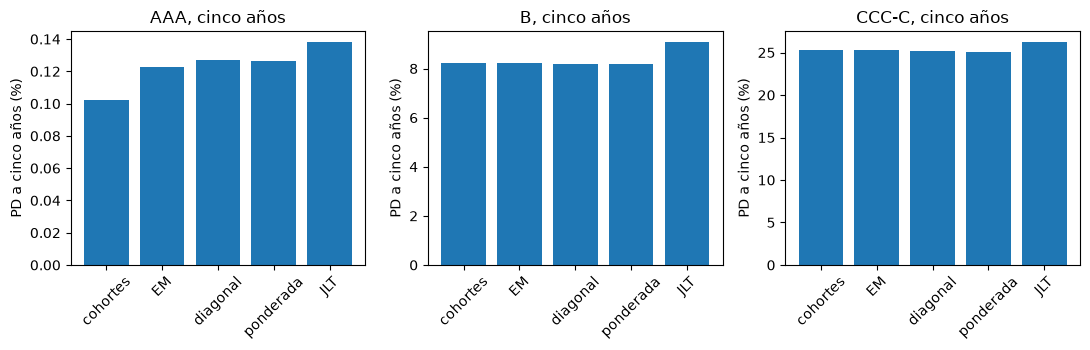

In [13]:
# Draw the five-year PD of three grades under each estimator
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, g in zip(axes, shown):
    ax.bar(range(len(five_year)), [100 * five_year[name][g] for name in five_year], color="tab:blue")
    ax.set_xticks(range(len(five_year)))
    ax.set_xticklabels([display[name] for name in five_year], rotation=45)
    ax.set_title(f"{grades[g]}, cinco años")
    ax.set_ylabel("PD a cinco años (%)")
fig.tight_layout()
plt.show()

Para B y CCC-C las cinco barras de la potencia de cohortes, EM, diagonal y ponderada tienen casi la misma altura, dentro de una fracción de punto, y JLT queda cerca de un punto sobre ellas: los estimadores coinciden donde hay datos, y la reparación que toma el logaritmo de la diagonal es la atípica. Para AAA las barras son del orden de una décima de punto porcentual y difieren en decenas de por ciento de sí mismas, siendo la potencia de cohortes la más baja, como predice el estudio de verdad conocida para un grado con un puñado de incumplimientos. La figura compara los estimadores propios del producto entre sí. No es una conciliación con una biblioteca externa, y no puede decir cuál estimador es el correcto en la matriz real, porque la verdad real se desconoce.

## Resultados

**Respuesta:** Para los mejores grados el estimador que conviene leer es el de duración, y en la matriz real de S&P la elección importa poco salvo en AAA y para JLT. Sobre datos de verdad conocida el estimador de duración tiene un RMSE relativo de 1,402 en AAA y una estimación máxima de 3,2 puntos base, mientras que el de cohortes tiene 7,090, devuelve exactamente cero en 0,98 de los conjuntos de datos y llega a 36,4 puntos base en el único conjunto con un incumplimiento; EM y las tres reparaciones tienen un error de tamaño parecido. En la matriz real la PD a cinco años de CCC-C es 25,2981, 25,2657, 25,1454 y 25,0877 por ciento con la potencia de cohortes, EM y las reparaciones diagonal y ponderada, frente a 26,1829 con JLT, y la de AAA va de 0,1025 a 0,1379.

- **Duración frente a cohortes, sobre una verdad conocida.** En AAA el estudio de 60 conjuntos de datos da al estimador de cohortes un sesgo relativo de -0,077 y un RMSE de 7,090 (error de Monte Carlo 3,475), y al de duración 0,266 y 1,402 (0,138). El error del estimador de cohortes está en un solo conjunto, de modo que su error de Monte Carlo es tan grande como el número. El estudio versionado de 200 conjuntos muestra lo mismo con menos ruido: el sesgo relativo en AAA es -0,44 para el estimador de cohortes y -0,06 para duración, +0,50 para EM y cerca de +0,6 para los estimadores diagonal, ponderado y JLT. De A a CCC-C los estimadores están cerca, y JLT tiene un sesgo de 0,19 a 0,25 de BBB a B.
- **EM y las reparaciones no agregan nada en el extremo delgado.** Leen las mismas fotos anuales que el estimador de cohortes y tienen su error en AAA (RMSE relativo 6,951 para EM, 7,210 y 7,156 para las reparaciones y 7,518 para JLT) con un sesgo positivo de 1,1 a 1,3 en este estudio, porque nunca devuelven exactamente cero. Un banco que tiene solo las tablas anuales de la agencia tiene estos y no el estimador de duración, que necesita historias de calificación.
- **Aalen-Johansen.** Su RMSE relativo es 2,313 en AAA y 0,202 en CCC-C, frente a 7,090 y 0,084 del estimador de cohortes y 1,402 y 0,073 de duración: paga por estimar un año solo desde ese año.
- **Condicionamiento macro.** La tasa de incumplimiento del grado especulativo promedia 0,0375; con una correlación supuesta de 0,12 los factores más bajos son 2009 (-1,72), 2002 (-1,42), 2001 (-1,35) y 2000 (-0,95), los más altos 2007 (1,15), 2006 (0,99), 2005 (0,85) y 2014 (0,70), y 14 de los 26 años son negativos. El producto lee este factor y prueba la estabilidad de la matriz; no ajusta una matriz condicionada.
- **En la matriz real los estimadores coinciden donde hay datos de sobra.** La PD a un año de B es 1,1731, 1,1731, 1,1727 y 1,1709 por ciento con la matriz de cohortes, EM y las dos reparaciones y 1,4664 con JLT; la de CCC-C es 8,0675, 8,0618, 8,0543 y 8,0190 frente a 8,2170. A cinco años la PD de B es 8,2143, 8,2142, 8,1917 y 8,1758 frente a 9,0631 con JLT.
- **La biblioteca de referencia.** La igualdad del estimador de cohortes con `transitionMatrix` es una prueba del motor (RV-415) que este notebook no vuelve a correr y no cuenta; la concordancia de arriba es la de los estimadores propios del producto entre sí.

Lo que este notebook no muestra: el efecto de la definición de incumplimiento y de los retiros sobre estas PD, ni la cobertura de los intervalos en grados delgados (notebook 10).

## Resumen

- El estimador de cohortes no puede ver la PD de AAA desde fotos anuales, y tampoco EM ni las reparaciones de la matriz; el estimador de duración sí puede, donde existen trayectorias, con un error del orden de la propia PD.
- Donde hay datos de sobra los estimadores coinciden dentro de una fracción de punto a cinco años; JLT queda cerca de un punto sobre ellos.
- Los estimadores se comparan por sesgo y RMSE con sus errores de Monte Carlo, sobre una verdad conocida; un estudio pequeño con el arnés muestra cómo surgen los números, y uno mayor los afirma.
- El producto lee el factor del ciclo de crédito y prueba la estabilidad de la matriz pero no ajusta ninguna matriz condicionada, y no corre ninguna conciliación con una biblioteca de referencia.

**Qué probar después.** Sube a 200 los conjuntos de datos del estudio del Paso 1 y mira bajar los errores estándar; luego lee el notebook 09.

## Referencias

- ESMA, CEREP publication of credit rating agency ratings and transitions. https://registers.esma.europa.eu/cerep-publication/
- Anderson, T. W. y Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1). https://doi.org/10.1214/aoms/1177707039
- Israel, R. B., Rosenthal, J. S. y Wei, J. Z. (2001), Finding generators for Markov chains via empirical transition matrices, Mathematical Finance 11(2). https://doi.org/10.1111/1467-9965.00114
- Schuermann, T. y Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Lando, D. y Skodeberg, T. M. (2002), Analyzing rating transitions and rating drift with continuous observations, Journal of Banking and Finance 26(2-3), doi 10.1016/S0378-4266(01)00228-X.
- Jarrow, R. A., Lando, D. y Turnbull, S. M. (1997), la aproximación de la ecuación (3) y el Lema 1, según los citan Israel, Rosenthal y Wei (2001) y la documentación del motor.
- Belkin, B., Suchower, S. y Forest, L. R. (1998), A one-parameter representation of credit risk and transition matrices, CreditMetrics Monitor, third quarter.
- Bladt, M. y Sørensen, M. (2005), Statistical inference for discretely observed Markov jump processes, Journal of the Royal Statistical Society B 67(3), 395-410.
- Smith, A. y dos Reis, G. (2018), Quantitative Finance, doi 10.1080/14697688.2017.1383627, para el generador EM.
- Morris, T. P., White, I. R. y Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11), doi 10.1002/sim.8086.